# Fashion-MNIST Clothing Classification with Neural Networks in PyTorch

**Goal:** Classify 32×32 grayscale images of clothing into 10 classes, and compare feed-forward and convolutional neural networks on the task.

**Data:** 52,500 labelled images derived from the [Fashion-MNIST dataset](https://github.com/zalandoresearch/fashion-mnist) by Zalando Research, about 5,250 per class.

**Approach:**
1. Train feed-forward networks (FNNs) of different depths, compare the Adam and SGD optimisers, and add batch normalisation and dropout.
2. Train two convolutional networks (CNNs).
3. Use the same procedure for every model: fixed random seeds and early stopping on validation loss.

**Result:** The improved CNN reached 89.28% validation accuracy and **89.66% accuracy on the held-out test set**, compared with 83.66% for the best FNN. Shirts are the hardest class (F1 0.71), most often confused with T-shirts.

**Tools:** Python, PyTorch, scikit-learn, pandas, NumPy, Matplotlib

### Contents
1. Data
2. Exploratory analysis
3. Evaluation setup
4. Feed-forward networks
5. Convolutional networks
6. Results summary
7. Final model on the test set
8. Conclusions and limitations
9. Predictions for unlabelled data

In [1]:
import copy
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix
from torch.utils.data import DataLoader, TensorDataset, random_split

%matplotlib inline

DATA_DIR = Path("data")
MODELS_DIR = Path("models")
MODELS_DIR.mkdir(exist_ok=True)

SEED = 42
BATCH_SIZE = 32
CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]


def set_seed(seed=SEED):
    """Make weight initialisation, dropout and batch shuffling reproducible."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


# Use a GPU when one is available (NVIDIA CUDA or Apple Silicon), otherwise the CPU
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print("PyTorch", torch.__version__, "| device:", DEVICE)

PyTorch 2.3.0+cpu | device: cpu


## 1. Data

`train.csv` holds 52,500 labelled images. Each row is one 32×32 grayscale image: 1,024 pixel values (0–255) followed by the `label` column (0–9). `evaluate.csv` holds 17,500 unlabelled images with an `ID` column, used only in the last section.

The labels follow the standard Fashion-MNIST classes:

| Label | Class | Label | Class |
|---|---|---|---|
| 0 | T-shirt/top | 5 | Sandal |
| 1 | Trouser | 6 | Shirt |
| 2 | Pullover | 7 | Sneaker |
| 3 | Dress | 8 | Bag |
| 4 | Coat | 9 | Ankle boot |

In [2]:
df = pd.read_csv(DATA_DIR / "train.csv")

print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Pixel value range:", df.drop(columns="label").values.min(), "-", df.drop(columns="label").values.max())

Shape: (52500, 1025)
Missing values: 0
Pixel value range: 0 - 255


## 2. Exploratory analysis

### Class balance

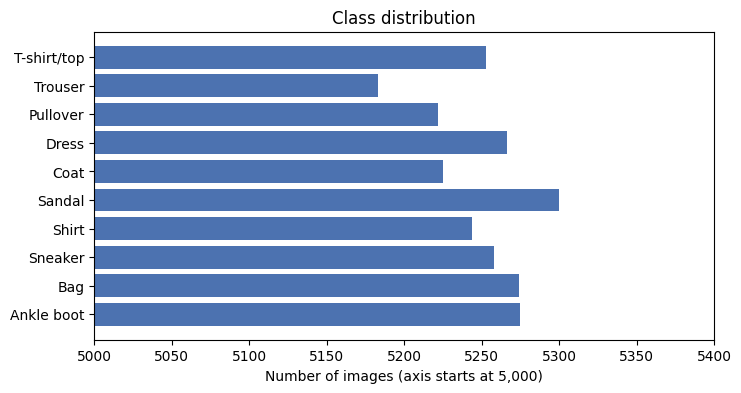

Smallest class: 5,183 images, largest: 5,300 images


In [3]:
counts = df["label"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(CLASS_NAMES, counts.values, color="#4c72b0")
ax.set_xlim(5000, counts.max() + 100)
ax.invert_yaxis()
ax.set_xlabel("Number of images (axis starts at 5,000)")
ax.set_title("Class distribution")
plt.show()

print(f"Smallest class: {counts.min():,} images, largest: {counts.max():,} images")

All ten classes have between 5,183 and 5,300 images, so the dataset is balanced and accuracy is a fair main metric.

### Sample images per class

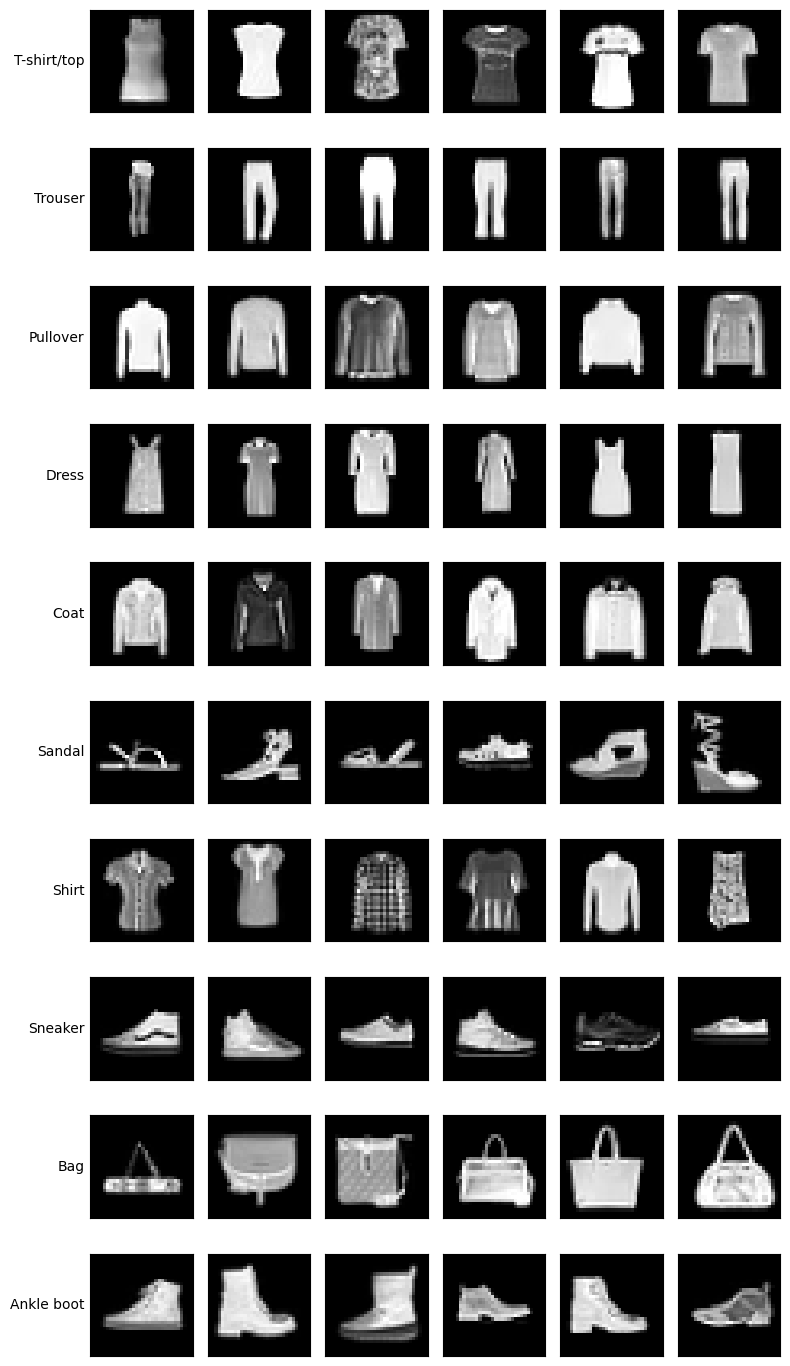

In [4]:
pixels = df.drop(columns="label").values
labels = df["label"].values

fig, axes = plt.subplots(10, 6, figsize=(8, 14))
for label in range(10):
    examples = pixels[labels == label][:6]
    for j, ax in enumerate(axes[label]):
        ax.imshow(examples[j].reshape(32, 32), cmap="gray")
        ax.set_xticks([]); ax.set_yticks([])
    axes[label, 0].set_ylabel(CLASS_NAMES[label], rotation=0, ha="right", va="center")
plt.tight_layout()
plt.show()

Most classes have a distinct outline (trousers, bags, sandals). T-shirts, pullovers, coats and shirts all share a similar upper-body shape and differ mainly in sleeves, collars and texture, so these classes are likely to be confused most often.

## 3. Evaluation setup

The images are converted once into a tensor of shape (N, 1, 32, 32) with values scaled to 0–1. The data is split into training (60%, 31,500 images), validation (20%, 10,500) and test (20%, 10,500) sets with a fixed seed.

Every model is trained with the same procedure:
- cross-entropy loss, batch size 32, at most 20 epochs;
- after each epoch, loss and accuracy are measured on the validation set;
- **early stopping:** the weights with the lowest validation loss are kept, and training stops when the validation loss has not improved for a set number of epochs (*patience*).

The test set is used only once, for the final model.

In [5]:
X_all = torch.tensor(pixels, dtype=torch.float32).view(-1, 1, 32, 32) / 255.0
y_all = torch.tensor(labels, dtype=torch.long)

dataset = TensorDataset(X_all, y_all)
split_gen = torch.Generator().manual_seed(SEED)
train_data, rest = random_split(dataset, [0.6, 0.4], generator=split_gen)
val_data, test_data = random_split(rest, [0.5, 0.5], generator=split_gen)

val_loader = DataLoader(val_data, batch_size=256)
test_loader = DataLoader(test_data, batch_size=256)

for name, part in [("Train", train_data), ("Validation", val_data), ("Test", test_data)]:
    print(f"{name:<11} {len(part):,} images")

Train       31,500 images
Validation  10,500 images
Test        10,500 images


### Training helpers

- `train_model` trains a model with early stopping, keeps the best weights, saves them to `models/<name>.pt` and records the result for the summary table in section 6.
- `evaluate` returns the loss and accuracy of a model on a data loader.
- `predict` returns the predicted class for every image in a loader.

Every model is moved to `DEVICE` (GPU if available) before its optimiser is created. Models are switched to evaluation mode (`model.eval()`) for validation and testing, so dropout is turned off and batch normalisation uses its stored statistics.

In [6]:
loss_fn = nn.CrossEntropyLoss()
summary = []


def count_params(model):
    return sum(p.numel() for p in model.parameters())


def evaluate(model, loader):
    """Average loss and accuracy of `model` on `loader`."""
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for images, targets in loader:
            images, targets = images.to(DEVICE), targets.to(DEVICE)
            outputs = model(images)
            total_loss += loss_fn(outputs, targets).item() * len(targets)
            correct += (outputs.argmax(1) == targets).sum().item()
            n += len(targets)
    return total_loss / n, correct / n


def predict(model, loader):
    """Predicted class for every image in `loader` (labels, if present, are ignored)."""
    model.eval()
    preds = []
    with torch.no_grad():
        for batch in loader:
            preds.extend(model(batch[0].to(DEVICE)).argmax(1).cpu().tolist())
    return np.array(preds)


def train_model(name, model, optimizer, max_epochs=20, patience=3):
    """Train with early stopping on validation loss. Returns the per-epoch history."""
    train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True,
                              generator=torch.Generator().manual_seed(SEED))
    history, best_loss, best_state, best_epoch, waited = [], float("inf"), None, 0, 0

    for epoch in range(1, max_epochs + 1):
        start = time.time()
        model.train()
        total_loss, correct, n = 0.0, 0, 0
        for images, targets in train_loader:
            images, targets = images.to(DEVICE), targets.to(DEVICE)
            optimizer.zero_grad()
            outputs = model(images)
            loss = loss_fn(outputs, targets)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(targets)
            correct += (outputs.argmax(1) == targets).sum().item()
            n += len(targets)

        val_loss, val_acc = evaluate(model, val_loader)
        history.append({"epoch": epoch, "train_loss": total_loss / n, "train_acc": correct / n,
                        "val_loss": val_loss, "val_acc": val_acc})

        improved = val_loss < best_loss
        if improved:
            best_loss, best_epoch, waited = val_loss, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            waited += 1
        print(f"Epoch {epoch:2d}  train loss {total_loss / n:.3f}  acc {correct / n:.3f}  |  "
              f"val loss {val_loss:.3f}  acc {val_acc:.3f}  ({time.time() - start:.0f}s){'  *' if improved else ''}")
        if waited > patience:
            print(f"Early stopping: no improvement for {waited} epochs.")
            break

    model.load_state_dict(best_state)
    torch.save(best_state, MODELS_DIR / f"{name}.pt")
    best = history[best_epoch - 1]
    summary.append({"Model": name, "Parameters": count_params(model), "Epochs trained": len(history),
                    "Best epoch": best_epoch, "Val loss": best["val_loss"], "Val accuracy": best["val_acc"]})
    print(f"Best epoch {best_epoch}: val loss {best['val_loss']:.3f}, val accuracy {best['val_acc']:.4f}")
    return pd.DataFrame(history)

## 4. Feed-forward networks

A feed-forward network (FNN) flattens each image into a vector of 1,024 pixels and passes it through fully connected layers. It ignores the 2-D structure of the image, so it has to learn separately that a pattern means the same thing in different positions. This makes it a reasonable baseline, but not the natural choice for images.

### 4.1 Small FNN

One hidden layer with 16 neurons, trained with Adam (learning rate 0.001).

In [7]:
class SmallFNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(32 * 32, 16), nn.ReLU(), nn.Linear(16, 10))

    def forward(self, x):
        return self.net(x)


set_seed()
model = SmallFNN().to(DEVICE)
print(f"Parameters: {count_params(model):,}")
hist_small = train_model("fnn_small_adam", model, torch.optim.Adam(model.parameters(), lr=1e-3))

Parameters: 16,570
Epoch  1  train loss 0.949  acc 0.675  |  val loss 0.780  acc 0.726  (2s)  *
Epoch  2  train loss 0.697  acc 0.752  |  val loss 0.697  acc 0.750  (2s)  *
Epoch  3  train loss 0.650  acc 0.769  |  val loss 0.665  acc 0.761  (2s)  *
Epoch  4  train loss 0.624  acc 0.779  |  val loss 0.647  acc 0.766  (3s)  *
Epoch  5  train loss 0.605  acc 0.785  |  val loss 0.637  acc 0.774  (2s)  *
Epoch  6  train loss 0.590  acc 0.789  |  val loss 0.643  acc 0.771  (2s)
Epoch  7  train loss 0.581  acc 0.792  |  val loss 0.627  acc 0.775  (3s)  *
Epoch  8  train loss 0.572  acc 0.795  |  val loss 0.619  acc 0.778  (3s)  *
Epoch  9  train loss 0.560  acc 0.801  |  val loss 0.631  acc 0.778  (3s)
Epoch 10  train loss 0.552  acc 0.804  |  val loss 0.605  acc 0.787  (2s)  *
Epoch 11  train loss 0.546  acc 0.806  |  val loss 0.594  acc 0.790  (2s)  *
Epoch 12  train loss 0.540  acc 0.810  |  val loss 0.611  acc 0.783  (2s)
Epoch 13  train loss 0.534  acc 0.812  |  val loss 0.603  acc 0.78

The small FNN reaches **79.03%** validation accuracy (best epoch 11). With only 16 hidden neurons it has little capacity: training accuracy stays around 81%, so the model underfits rather than overfits.

### 4.2 Deeper FNN

Three hidden layers (256, 64 and 16 neurons), also trained with Adam.

In [8]:
class DeepFNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 32, 256), nn.ReLU(),
            nn.Linear(256, 64), nn.ReLU(),
            nn.Linear(64, 16), nn.ReLU(),
            nn.Linear(16, 10),
        )

    def forward(self, x):
        return self.net(x)


set_seed()
model = DeepFNN().to(DEVICE)
print(f"Parameters: {count_params(model):,}")
hist_deep = train_model("fnn_deep_adam", model, torch.optim.Adam(model.parameters(), lr=1e-3))

Parameters: 280,058
Epoch  1  train loss 0.853  acc 0.681  |  val loss 0.681  acc 0.752  (6s)  *
Epoch  2  train loss 0.590  acc 0.784  |  val loss 0.588  acc 0.782  (6s)  *
Epoch  3  train loss 0.523  acc 0.804  |  val loss 0.555  acc 0.802  (6s)  *
Epoch  4  train loss 0.481  acc 0.822  |  val loss 0.515  acc 0.815  (6s)  *
Epoch  5  train loss 0.451  acc 0.832  |  val loss 0.490  acc 0.825  (6s)  *
Epoch  6  train loss 0.428  acc 0.842  |  val loss 0.482  acc 0.825  (6s)  *
Epoch  7  train loss 0.404  acc 0.848  |  val loss 0.469  acc 0.827  (6s)  *
Epoch  8  train loss 0.389  acc 0.852  |  val loss 0.465  acc 0.829  (6s)  *
Epoch  9  train loss 0.371  acc 0.861  |  val loss 0.465  acc 0.831  (6s)  *
Epoch 10  train loss 0.358  acc 0.865  |  val loss 0.478  acc 0.828  (6s)
Epoch 11  train loss 0.345  acc 0.870  |  val loss 0.462  acc 0.837  (6s)  *
Epoch 12  train loss 0.333  acc 0.873  |  val loss 0.489  acc 0.825  (6s)
Epoch 13  train loss 0.325  acc 0.876  |  val loss 0.465  acc 

The deeper FNN improves validation accuracy to **83.66%**. Training accuracy (about 88% at the end) is now clearly higher than validation accuracy, so the extra capacity starts to overfit, and early stopping ends training after epoch 15.

### 4.3 Optimisers: Adam vs. SGD

The small FNN from 4.1 is trained again with plain stochastic gradient descent (SGD). Two settings are compared:
- **plain SGD** with the same learning rate as Adam (0.001), and
- **SGD with momentum** (learning rate 0.01, momentum 0.9), a common setting that makes the comparison fairer.

In [9]:
set_seed()
model = SmallFNN().to(DEVICE)
hist_sgd = train_model("fnn_small_sgd", model, torch.optim.SGD(model.parameters(), lr=1e-3))

Epoch  1  train loss 2.197  acc 0.250  |  val loss 2.082  acc 0.344  (3s)  *
Epoch  2  train loss 1.964  acc 0.373  |  val loss 1.838  acc 0.412  (2s)  *
Epoch  3  train loss 1.717  acc 0.512  |  val loss 1.607  acc 0.562  (2s)  *
Epoch  4  train loss 1.505  acc 0.592  |  val loss 1.426  acc 0.598  (2s)  *
Epoch  5  train loss 1.347  acc 0.609  |  val loss 1.298  acc 0.606  (2s)  *
Epoch  6  train loss 1.239  acc 0.619  |  val loss 1.210  acc 0.614  (2s)  *
Epoch  7  train loss 1.165  acc 0.627  |  val loss 1.149  acc 0.621  (2s)  *
Epoch  8  train loss 1.111  acc 0.634  |  val loss 1.103  acc 0.629  (2s)  *
Epoch  9  train loss 1.069  acc 0.643  |  val loss 1.067  acc 0.635  (2s)  *
Epoch 10  train loss 1.036  acc 0.649  |  val loss 1.037  acc 0.640  (2s)  *
Epoch 11  train loss 1.008  acc 0.656  |  val loss 1.012  acc 0.648  (2s)  *
Epoch 12  train loss 0.983  acc 0.663  |  val loss 0.990  acc 0.654  (2s)  *
Epoch 13  train loss 0.962  acc 0.669  |  val loss 0.971  acc 0.661  (2s)  *

In [10]:
set_seed()
model = SmallFNN().to(DEVICE)
hist_sgd_m = train_model("fnn_small_sgd_momentum", model, torch.optim.SGD(model.parameters(), lr=1e-2, momentum=0.9))

Epoch  1  train loss 0.922  acc 0.666  |  val loss 0.765  acc 0.729  (2s)  *
Epoch  2  train loss 0.689  acc 0.749  |  val loss 0.714  acc 0.733  (2s)  *
Epoch  3  train loss 0.644  acc 0.763  |  val loss 0.643  acc 0.769  (2s)  *
Epoch  4  train loss 0.616  acc 0.776  |  val loss 0.627  acc 0.775  (2s)  *
Epoch  5  train loss 0.595  acc 0.784  |  val loss 0.618  acc 0.778  (2s)  *
Epoch  6  train loss 0.580  acc 0.790  |  val loss 0.637  acc 0.776  (2s)
Epoch  7  train loss 0.569  acc 0.791  |  val loss 0.649  acc 0.760  (2s)
Epoch  8  train loss 0.556  acc 0.798  |  val loss 0.614  acc 0.785  (2s)  *
Epoch  9  train loss 0.547  acc 0.803  |  val loss 0.623  acc 0.779  (2s)
Epoch 10  train loss 0.539  acc 0.803  |  val loss 0.616  acc 0.780  (2s)
Epoch 11  train loss 0.536  acc 0.804  |  val loss 0.575  acc 0.801  (2s)  *
Epoch 12  train loss 0.527  acc 0.808  |  val loss 0.586  acc 0.788  (2s)
Epoch 13  train loss 0.525  acc 0.808  |  val loss 0.591  acc 0.783  (2s)
Epoch 14  train l

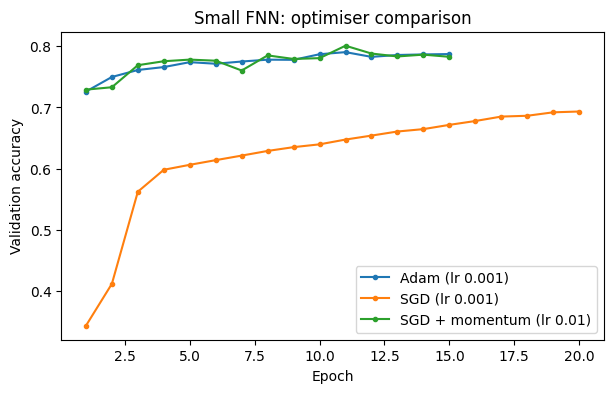

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
for label, h in [("Adam (lr 0.001)", hist_small), ("SGD (lr 0.001)", hist_sgd), ("SGD + momentum (lr 0.01)", hist_sgd_m)]:
    ax.plot(h["epoch"], h["val_acc"], ".-", label=label)
ax.set_xlabel("Epoch")
ax.set_ylabel("Validation accuracy")
ax.set_title("Small FNN: optimiser comparison")
ax.legend()
plt.show()

- **Plain SGD** with learning rate 0.001 learns slowly. After 20 epochs it reaches only **69.33%** and is still improving: the learning rate is too small for this number of epochs.
- **SGD with momentum** reaches **80.08%**, slightly better than Adam (79.03%) on the same network.

The optimiser's settings matter more than the choice of optimiser itself: with a suitable learning rate and momentum, SGD keeps up with Adam here. Adam is used for the remaining models because it works well with its default settings.

### 4.4 Regularised deeper FNN

The deeper FNN from 4.2 with two regularisation techniques added after each hidden layer:
- **batch normalisation**, which normalises each layer's outputs and usually makes training faster and more stable;
- **dropout** (30%), which randomly switches off neurons during training so the network cannot rely on a few of them.

In [12]:
class RegularisedFNN(nn.Module):
    def __init__(self, dropout=0.3):
        super().__init__()
        def block(n_in, n_out):
            return [nn.Linear(n_in, n_out), nn.BatchNorm1d(n_out), nn.ReLU(), nn.Dropout(dropout)]
        self.net = nn.Sequential(nn.Flatten(), *block(32 * 32, 256), *block(256, 64), *block(64, 16), nn.Linear(16, 10))

    def forward(self, x):
        return self.net(x)


set_seed()
model = RegularisedFNN().to(DEVICE)
print(f"Parameters: {count_params(model):,}")
hist_reg = train_model("fnn_deep_regularised", model, torch.optim.Adam(model.parameters(), lr=1e-3))

Parameters: 280,730
Epoch  1  train loss 1.216  acc 0.593  |  val loss 0.734  acc 0.721  (7s)  *
Epoch  2  train loss 0.903  acc 0.676  |  val loss 0.639  acc 0.762  (7s)  *
Epoch  3  train loss 0.831  acc 0.702  |  val loss 0.589  acc 0.786  (7s)  *
Epoch  4  train loss 0.783  acc 0.724  |  val loss 0.574  acc 0.795  (7s)  *
Epoch  5  train loss 0.757  acc 0.737  |  val loss 0.552  acc 0.801  (7s)  *
Epoch  6  train loss 0.723  acc 0.748  |  val loss 0.549  acc 0.798  (7s)  *
Epoch  7  train loss 0.710  acc 0.751  |  val loss 0.519  acc 0.808  (7s)  *
Epoch  8  train loss 0.696  acc 0.761  |  val loss 0.525  acc 0.804  (7s)
Epoch  9  train loss 0.679  acc 0.761  |  val loss 0.501  acc 0.814  (8s)  *
Epoch 10  train loss 0.666  acc 0.770  |  val loss 0.493  acc 0.819  (8s)  *
Epoch 11  train loss 0.653  acc 0.773  |  val loss 0.495  acc 0.820  (7s)
Epoch 12  train loss 0.643  acc 0.775  |  val loss 0.483  acc 0.823  (7s)  *
Epoch 13  train loss 0.640  acc 0.778  |  val loss 0.481  acc 

The regularised FNN reaches **83.19%**, about the same as without regularisation (83.66%). Its validation loss was still falling at epoch 20, so it may need more epochs to benefit. Training accuracy (79.5%) is lower than validation accuracy (83.2%) because dropout is active only during training. Regularisation does not remove the main limitation of FNNs: they ignore the 2-D structure of the image.

## 5. Convolutional networks

A convolutional network (CNN) slides small filters over the image, so it detects local patterns such as edges, sleeves or collars wherever they appear. Pooling layers then reduce the spatial size while the number of channels grows. This uses the 2-D structure of the image directly, which makes CNNs the standard choice for image classification.

### 5.1 First CNN

Two convolutional blocks (32 and 64 filters, each followed by max pooling and batch normalisation), then three fully connected layers with dropout (50%) after the first one. The fully connected part has no activation functions, so after the convolutional layers it acts as a single linear classifier.

In [13]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.BatchNorm2d(32),  # 32x32 -> 16x16
            nn.Conv2d(32, 64, kernel_size=3), nn.ReLU(), nn.MaxPool2d(2), nn.BatchNorm2d(64),            # 16x16 -> 14x14 -> 7x7
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(64 * 7 * 7, 600), nn.Dropout(0.5), nn.Linear(600, 120), nn.Linear(120, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


set_seed()
model = SimpleCNN().to(DEVICE)
print(f"Parameters: {count_params(model):,}")
hist_cnn1 = train_model("cnn_simple", model, torch.optim.Adam(model.parameters(), lr=1e-3), patience=5)

Parameters: 1,974,538
Epoch  1  train loss 0.596  acc 0.792  |  val loss 0.512  acc 0.812  (48s)  *
Epoch  2  train loss 0.420  acc 0.850  |  val loss 0.470  acc 0.837  (51s)  *
Epoch  3  train loss 0.365  acc 0.868  |  val loss 0.435  acc 0.846  (52s)  *
Epoch  4  train loss 0.334  acc 0.882  |  val loss 0.398  acc 0.865  (52s)  *
Epoch  5  train loss 0.305  acc 0.889  |  val loss 0.422  acc 0.864  (53s)
Epoch  6  train loss 0.281  acc 0.898  |  val loss 0.390  acc 0.874  (53s)  *
Epoch  7  train loss 0.253  acc 0.908  |  val loss 0.413  acc 0.865  (52s)
Epoch  8  train loss 0.246  acc 0.911  |  val loss 0.485  acc 0.843  (52s)
Epoch  9  train loss 0.225  acc 0.917  |  val loss 0.423  acc 0.871  (52s)
Epoch 10  train loss 0.207  acc 0.924  |  val loss 0.439  acc 0.865  (52s)
Epoch 11  train loss 0.194  acc 0.929  |  val loss 0.424  acc 0.873  (53s)
Epoch 12  train loss 0.180  acc 0.935  |  val loss 0.452  acc 0.869  (52s)
Early stopping: no improvement for 6 epochs.
Best epoch 6: val 

The first CNN reaches **87.38%** validation accuracy, almost 4 points above the best FNN. It overfits quickly, though: the best epoch is 6, and after that training accuracy keeps rising (to 93.5%) while validation loss gets worse.

### 5.2 Improved CNN

Changes compared with 5.1:
- batch normalisation is placed **before** the activation, the more common order;
- **ReLU activations** are added between the fully connected layers, so the classifier part can learn non-linear combinations of features;
- **dropout** (25%) is applied after each block and between the fully connected layers, spreading regularisation through the whole network.

In [14]:
class ImprovedCNN(nn.Module):
    def __init__(self, num_classes=10, dropout=0.25):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),  # 32x32 -> 16x16
            nn.Dropout(dropout),
            nn.Conv2d(32, 64, kernel_size=3), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),            # 16x16 -> 14x14 -> 7x7
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Dropout(dropout),
            nn.Linear(64 * 7 * 7, 600), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(600, 120), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(120, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


set_seed()
model = ImprovedCNN().to(DEVICE)
print(f"Parameters: {count_params(model):,}")
hist_cnn2 = train_model("cnn_improved", model, torch.optim.Adam(model.parameters(), lr=1e-3), patience=5)

Parameters: 1,974,538
Epoch  1  train loss 0.678  acc 0.744  |  val loss 0.523  acc 0.804  (58s)  *
Epoch  2  train loss 0.490  acc 0.819  |  val loss 0.435  acc 0.835  (58s)  *
Epoch  3  train loss 0.431  acc 0.843  |  val loss 0.375  acc 0.858  (58s)  *
Epoch  4  train loss 0.394  acc 0.856  |  val loss 0.377  acc 0.857  (58s)
Epoch  5  train loss 0.368  acc 0.866  |  val loss 0.341  acc 0.881  (58s)  *
Epoch  6  train loss 0.342  acc 0.874  |  val loss 0.348  acc 0.878  (61s)
Epoch  7  train loss 0.323  acc 0.881  |  val loss 0.340  acc 0.871  (64s)  *
Epoch  8  train loss 0.309  acc 0.884  |  val loss 0.310  acc 0.890  (58s)  *
Epoch  9  train loss 0.293  acc 0.891  |  val loss 0.356  acc 0.872  (62s)
Epoch 10  train loss 0.280  acc 0.896  |  val loss 0.302  acc 0.891  (60s)  *
Epoch 11  train loss 0.268  acc 0.900  |  val loss 0.291  acc 0.893  (58s)  *
Epoch 12  train loss 0.265  acc 0.902  |  val loss 0.297  acc 0.893  (57s)
Epoch 13  train loss 0.249  acc 0.906  |  val loss 0.3

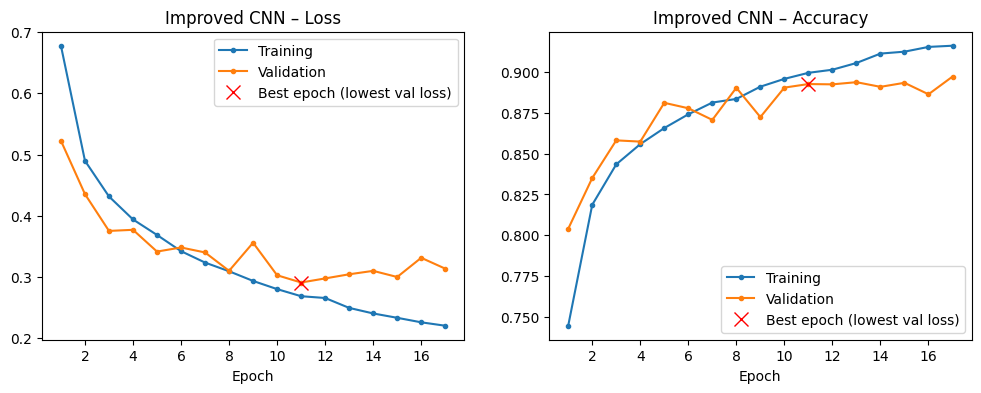

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric, title in [(axes[0], "loss", "Loss"), (axes[1], "acc", "Accuracy")]:
    ax.plot(hist_cnn2["epoch"], hist_cnn2[f"train_{metric}"], ".-", label="Training")
    ax.plot(hist_cnn2["epoch"], hist_cnn2[f"val_{metric}"], ".-", label="Validation")
    best = hist_cnn2["val_loss"].idxmin()
    ax.plot(hist_cnn2.loc[best, "epoch"], hist_cnn2.loc[best, f"val_{metric}"], "x", color="red", markersize=10,
            label="Best epoch (lowest val loss)")
    ax.set_xlabel("Epoch")
    ax.set_title(f"Improved CNN – {title}")
    ax.legend()
plt.show()

The improved CNN reaches **89.28%** validation accuracy at epoch 11 (lowest validation loss 0.291). Training and validation curves stay close for longer than with the first CNN, so the added dropout and activations reduce overfitting. Both CNNs have the same number of parameters (1,974,538): the gain comes only from the layer order, the activations and the dropout.

## 6. Results summary

All models, sorted by validation accuracy at their best epoch.

In [16]:
summary_df = (pd.DataFrame(summary)
              .sort_values("Val accuracy", ascending=False)
              .reset_index(drop=True))
summary_df.style.format({"Parameters": "{:,}", "Val loss": "{:.3f}", "Val accuracy": "{:.2%}"}).hide(axis="index")

Model,Parameters,Epochs trained,Best epoch,Val loss,Val accuracy
cnn_improved,"1,974,538",17,11,0.291,89.28%
cnn_simple,"1,974,538",12,6,0.390,87.38%
fnn_deep_adam,"280,058",15,11,0.462,83.66%
fnn_deep_regularised,"280,730",20,20,0.453,83.19%
fnn_small_sgd_momentum,"16,570",15,11,0.575,80.08%
fnn_small_adam,"16,570",15,11,0.594,79.03%
fnn_small_sgd,"16,570",20,20,0.876,69.33%


CNNs clearly beat FNNs: the improved CNN is 5.6 points above the best FNN. Most of the gain comes from using convolutions. Changes to the training setup (optimiser, regularisation) moved FNN accuracy by only about one point.

## 7. Final model on the test set

The model with the highest validation accuracy is selected and evaluated once on the untouched test set.

In [18]:
final_name = summary_df.loc[0, "Model"]
print("Selected model:", final_name)

MODEL_CLASSES = {
    "fnn_small_adam": SmallFNN, "fnn_small_sgd": SmallFNN, "fnn_small_sgd_momentum": SmallFNN,
    "fnn_deep_adam": DeepFNN, "fnn_deep_regularised": RegularisedFNN,
    "cnn_simple": SimpleCNN, "cnn_improved": ImprovedCNN,
}
final_model = MODEL_CLASSES[final_name]().to(DEVICE)
final_model.load_state_dict(torch.load(MODELS_DIR / f"{final_name}.pt", map_location=DEVICE))

test_loss, test_acc = evaluate(final_model, test_loader)
y_test = np.array([label for _, targets in test_loader for label in targets.tolist()])
y_pred = predict(final_model, test_loader)
print(f"Test loss {test_loss:.3f}, test accuracy {test_acc:.4f}")

Selected model: cnn_improved
Test loss 0.276, test accuracy 0.8966


In [19]:
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=3))

              precision    recall  f1-score   support

 T-shirt/top      0.825     0.853     0.839      1089
     Trouser      0.988     0.984     0.986      1039
    Pullover      0.843     0.836     0.840      1024
       Dress      0.885     0.914     0.899      1031
        Coat      0.790     0.875     0.830      1022
      Sandal      0.989     0.961     0.975      1081
       Shirt      0.769     0.662     0.712      1072
     Sneaker      0.918     0.973     0.945      1076
         Bag      0.990     0.976     0.983       993
  Ankle boot      0.971     0.938     0.954      1073

    accuracy                          0.897     10500
   macro avg      0.897     0.897     0.896     10500
weighted avg      0.897     0.897     0.896     10500



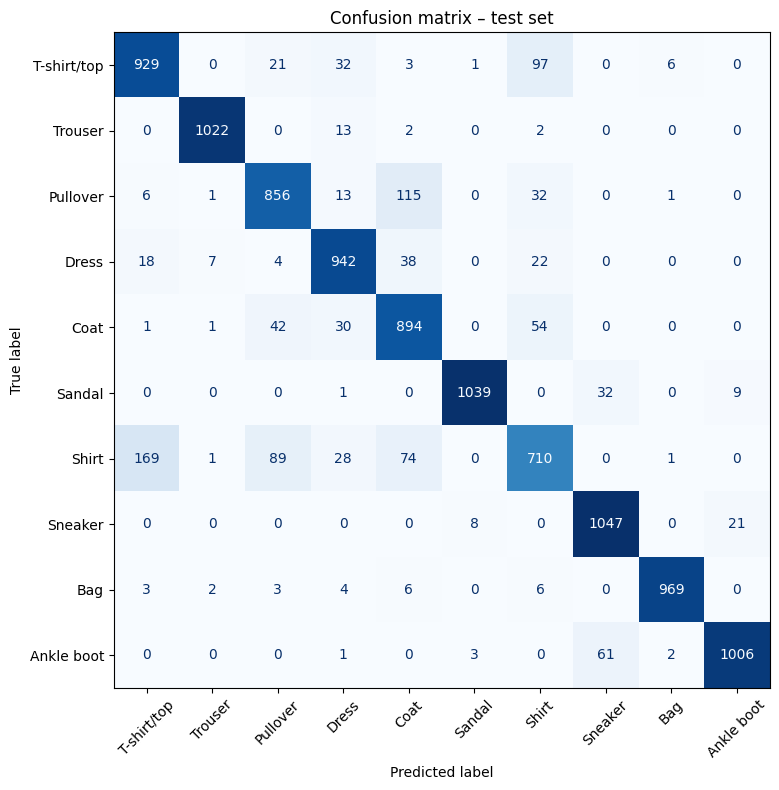

In [20]:
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=CLASS_NAMES).plot(
    ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45)
ax.set_title("Confusion matrix – test set")
plt.tight_layout()
plt.show()

In [21]:
cm = confusion_matrix(y_test, y_pred)
np.fill_diagonal(cm, 0)
pairs = [(cm[i, j], CLASS_NAMES[i], CLASS_NAMES[j]) for i in range(10) for j in range(10) if cm[i, j] > 0]
print("Most frequent mistakes (true class -> predicted class):")
for count, true, pred in sorted(pairs, reverse=True)[:6]:
    print(f"  {true:<12} -> {pred:<12} {count}")

Most frequent mistakes (true class -> predicted class):
  Shirt        -> T-shirt/top  169
  Pullover     -> Coat         115
  T-shirt/top  -> Shirt        97
  Shirt        -> Pullover     89
  Shirt        -> Coat         74
  Ankle boot   -> Sneaker      61


Test accuracy is **89.66%**, close to the validation accuracy (89.28%), so the validation results were a reliable estimate.

- Trousers, bags and sandals are almost always classified correctly (F1 at least 0.975).
- **Shirts are by far the hardest class** (recall 66%, F1 0.71). The most common mistakes are shirts predicted as T-shirts (169), pullovers predicted as coats (115) and T-shirts predicted as shirts (97). These classes share the same upper-body outline and differ mainly in small details such as collars and buttons, which are hard to see at 32×32 pixels.
- Among shoes, the main mistakes are ankle boots predicted as sneakers (61) and sandals predicted as sneakers (32).

## 8. Conclusions and limitations

**Findings**
- The improved CNN is the best model, with **89.66% test accuracy**. The best FNN reached 83.66% on validation.
- Convolutions matter most. Making the FNN deeper helped (79.0% → 83.7%), but batch normalisation and dropout added nothing further within 20 epochs.
- SGD with momentum matched Adam on the small FNN. Plain SGD with a small learning rate was simply too slow.
- Errors concentrate in four similar upper-body classes: shirt, T-shirt, pullover and coat.

**Limitations**
- Each model was trained once, with one seed. Differences of about one point or less (e.g. SGD with momentum vs. Adam) may be due to chance.
- Training was capped at 20 epochs, and the regularised FNN was still improving at the end.
- The CNN architecture and hyperparameters (learning rate, dropout rate, number of filters) were not tuned systematically.
- Data augmentation, such as small shifts of the images, was not tried. It is a common way to reduce overfitting in CNNs.

## 9. Predictions for unlabelled data

`evaluate.csv` contains 17,500 images without labels. The final model predicts a class for each of them, and the predictions are saved to `results.csv` together with each image's `ID`.

In [22]:
df_evaluate = pd.read_csv(DATA_DIR / "evaluate.csv")
print("Shape:", df_evaluate.shape)
print("Missing values:", df_evaluate.isnull().sum().sum())

X_eval = torch.tensor(df_evaluate.drop(columns="ID").values, dtype=torch.float32).view(-1, 1, 32, 32) / 255.0
eval_loader = DataLoader(TensorDataset(X_eval), batch_size=256)
predictions = predict(final_model, eval_loader)

df_result = pd.DataFrame({"ID": df_evaluate["ID"], "label": predictions})
df_result.to_csv("results.csv", index=False)

print(df_result["label"].map(dict(enumerate(CLASS_NAMES))).value_counts())

Shape: (17500, 1025)
Missing values: 0
label
Coat           1935
Sneaker        1829
T-shirt/top    1813
Trouser        1813
Dress          1762
Pullover       1750
Bag            1710
Ankle boot     1692
Sandal         1636
Shirt          1560
Name: count, dtype: int64
